<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Torch Tensors in 1D</h1>


<h2>Objective</h2><ul><li> How tensor operations work in pytorch.</li></ul> 


<h2>Table of Contents</h2>


<p>In this lab, you will learn the basics of tensor operations. Tensors are an essential part of PyTorch; there are complex mathematical objects in and of themselves. Fortunately, most of the intricacies are not necessary. In this section, you will compare them to vectors and numpy arrays.</p>
<ul>
    <li><a href="#Types-and-Shape">Types and Shape</a></li>
    <li><a href="#Indexing-and-Slicing">Indexing and Slicing</a></li>
    <li><a href="#Tensor-Functions">Tensor Functions</a></li>
    <li><a href="#Tensor-Operations">Tensor Operations</a></li>
</ul>

<p>Estimated Time Needed: <b>25 min</b></p>
<hr>


# <h2>Preparation</h2>


Import the following libraries that you'll use for this lab:


In [1]:
%%time
# %pip install pandas numpy matplotlib
# %pip install torch==2.8.0+cpu torchvision==0.23.0+cpu torchaudio==2.8.0+cpu \
#    --index-url https://download.pytorch.org/whl/cpu
%pip install torch


    

Note: you may need to restart the kernel to use updated packages.
CPU times: total: 0 ns
Wall time: 6.21 s


In [ ]:
# These are the libraries will be used for this lab.
import numpy as np 
import pandas as pd
import torch # 

import matplotlib.pyplot as plt
%matplotlib inline  

Check PyTorch version:


In [3]:
torch.__version__

'2.12.1+cpu'

This is the function for plotting diagrams. You will use this function to plot the vectors in Coordinate system.


In [4]:
# Plot vecotrs, please keep the parameters in the same length
# @param: Vectors = [{"vector": vector variable, "name": name of vector, "color": color of the vector on diagram}]
    
def plotVec(vectors):
    ax = plt.axes()  # Create a new axes object
    
    # For loop to draw the vectors
    for vec in vectors:
        ax.arrow(0, 0, *vec["vector"], head_width = 0.05,color = vec["color"], head_length = 0.1) 
        # Draw the vector as an arrow
        plt.text(*(vec["vector"] + 0.1), vec["name"]) # Add text label for the vector
    
    plt.ylim(-2,2)  # Set the y-axis limits
    plt.xlim(-2,2)  # Set the x-axis limits

<!--Empty Space for separating topics-->


<h2 id="Types_Shape">Types and Shape</h2>


You can find the type of the following list of integers <i>[0, 1, 2, 3, 4]</i> by applying the constructor <code>torch.tensor()</code>:


In [5]:
# Convert a integer list with length 5 to a tensor

ints_to_tensor = torch.tensor([0, 1, 2, 3, 4]) # Convert the list to a tensor
print("The dtype of tensor object after converting it to tensor: ", ints_to_tensor.dtype) 
# Print the data type of the tensor
print("The type of tensor object after converting it to tensor: ", ints_to_tensor.type()) 
# Print the type of the tensor

The dtype of tensor object after converting it to tensor:  torch.int64
The type of tensor object after converting it to tensor:  torch.LongTensor


As a result, the integer list has been converted to a long tensor.


The Python type is still <code>torch.Tensor</code>:


In [6]:
type(ints_to_tensor) # Print the type of the tensor object

torch.Tensor

<!--Empty Space for separate topics-->


You can find the type of this float list <i>[0.0, 1.0, 2.0, 3.0, 4.0]</i> by applying the method <code>torch.tensor()</code>:


In [7]:
# Convert a float list with length 5 to a tensor

floats_to_tensor = torch.tensor([0.0, 1.0, 2.0, 3.0, 4.0]) # Convert the list to a tensor
print("The dtype of tensor object after converting it to tensor: ", floats_to_tensor.dtype) 
# Print the data type of the tensor
print("The type of tensor object after converting it to tensor: ", floats_to_tensor.type()) 
# Print the type of the tensor

The dtype of tensor object after converting it to tensor:  torch.float32
The type of tensor object after converting it to tensor:  torch.FloatTensor


The float list is converted to a float tensor.


In [8]:
list_floats=[0.0, 1.0, 2.0, 3.0, 4.0] # Create a list of floats

floats_int_tensor=torch.tensor(list_floats,dtype=torch.int64) # Convert the list of floats to a tensor with integer data type


In [10]:
print("The dtype of tensor object is: ", floats_int_tensor.dtype) # Print the data type of the tensor object (converted from float to tensor with integer data type)
print("The type of tensor object is: ", floats_int_tensor.type()) # Print the type of the tensor object (converted from float to tensor with integer data type)
print("The printed values are the dtype, and type of the tensor objects, which are converted from float to tensor with integer data type")

The dtype of tensor object is:  torch.int64
The type of tensor object is:  torch.LongTensor
The printed values are the dtype, and type of the tensor objects, which are converted from float to tensor with integer data type


<b>Note: The elements in the list that will be converted to tensor must have the same type.</b>


<!--Empty Space for separating topics-->


From the previous examples, you see that <code>torch.tensor()</code> converts the list to the tensor type, which is similar to the original list type. However, what if you want to convert the list to a certain tensor type? <code>torch</code> contains the methods required to do this conversion. The following code  converts an integer list to float tensor:


In [12]:
# Convert a integer list with length 5 to float tensor

new_float_tensor = torch.FloatTensor([0, 1, 2, 3, 4]) # Convert the list to a float tensor
new_float_tensor.type() # Print the type of the new float tensor
print("The type of the new_float_tensor:", new_float_tensor.type()) # Print the type of the new float tensor

The type of the new_float_tensor: torch.FloatTensor


In [13]:
new_float_tensor = torch.FloatTensor([0, 1, 2, 3, 4]) # Convert the list to a float tensor

<!--Empty Space for separating topics-->


You can also convert an existing tensor object (<code><i>tensor_obj</i></code>) to another tensor type. Convert the integer tensor to a float tensor:


In [14]:
# Another method to convert the integer list to float tensor

old_int_tensor = torch.tensor([0, 1, 2, 3, 4]) # Convert the list to a tensor
new_float_tensor = old_int_tensor.type(torch.FloatTensor) # Convert the integer tensor to a float tensor
print("The type of the new_float_tensor:", new_float_tensor.type()) # Print the type of the new float tensor

The type of the new_float_tensor: torch.FloatTensor


<!--Empty Space for separating topics-->


The <code><i>tensor_obj</i>.size()</code> helps you to find out the size of the <code><i>tensor_obj</i></code>.
The <code><i>tensor_obj</i>.ndimension()</code> shows the dimension of the tensor object.


In [15]:
# Introduce the tensor_obj.size() & tensor_ndimension.size() methods

print("The size of the new_float_tensor: ", new_float_tensor.size()) # Print the size of the new float tensor
print("The dimension of the new_float_tensor: ",new_float_tensor.ndimension()) # Print the dimension of the new float tensor

The size of the new_float_tensor:  torch.Size([5])
The dimension of the new_float_tensor:  1


<!--Empty Space for separating topics-->


The <code><i>tensor_obj</i>.view(<i>row, column</i>)</code> is used for reshaping a tensor object.<br>


What if you have a tensor object with <code>torch.Size([5])</code> as a <code>new_float_tensor</code> as shown in the previous example?<br>
After you execute <code>new_float_tensor.view(5, 1)</code>, the size of <code>new_float_tensor</code> will be <code>torch.Size([5, 1])</code>.<br>
This means that the tensor object <code>new_float_tensor</code> has been reshaped from a one-dimensional  tensor object with 5 elements to a two-dimensional tensor object with 5 rows and 1 column.


In [16]:
# Introduce the tensor_obj.view(row, column) method

twoD_float_tensor = new_float_tensor.view(5, 1) # Reshape the new float tensor to a 2D tensor with 5 rows and 1 column
print("Original Size: ", new_float_tensor.size()) # Print the original size of the new float tensor
print("Size after view method", twoD_float_tensor.size()) # Print the size of the new float tensor after reshaping it to a 2D tensor

Original Size:  torch.Size([5])
Size after view method torch.Size([5, 1])


Note that the original size is 5. The tensor after reshaping becomes a 5X1 tensor analog to a column vector.


<b>Note: The number of elements in a tensor must remain constant after applying view.</b>


<!--Empty Space for separating topics-->


What if you have a tensor with dynamic size but you want to reshape it? You can use <b>-1</b> to do just that.


In [17]:
# Introduce the use of -1 in tensor_obj.view(row, column) method

twoD_float_tensor = new_float_tensor.view(-1, 1) # Reshape the new float tensor to a 2D tensor with an inferred number of rows and 1 column
print("Original Size: ", new_float_tensor.size()) # Print the original size of the new float tensor
print("Size after view method", twoD_float_tensor.size()) # Print the size of the new float tensor after reshaping it to a 2D tensor

Original Size:  torch.Size([5])
Size after view method torch.Size([5, 1])


You get the same result as the previous example. The <b>-1</b> can represent any size. However, be careful because you can set only one argument as <b>-1</b>.


<!--Empty Space for separating topics-->


You can also convert a <b>numpy</b> array to a <b>tensor</b>, for example: 


In [18]:
# Convert a numpy array to a tensor:

numpy_array = np.array([0.0, 1.0, 2.0, 3.0, 4.0]) # Create a numpy array
new_tensor = torch.from_numpy(numpy_array) # Convert the numpy array to a tensor

print("The dtype of new tensor: ", new_tensor.dtype) # Print the data type of the new tensor
print("The type of new tensor: ", new_tensor.type()) # Print the type of the new tensor

The dtype of new tensor:  torch.float64
The type of new tensor:  torch.DoubleTensor


<!--Empty Space for separating topics-->


Converting a <b>tensor</b> to a <b>numpy</b> is also supported in PyTorch. The syntax is shown below:


In [19]:
# Convert a tensor to a numpy array

back_to_numpy = new_tensor.numpy() # Convert the tensor back to a numpy array
print("The numpy array from tensor: ", back_to_numpy) # Print the numpy array converted from the tensor
print("The dtype of numpy array: ", back_to_numpy.dtype) # Print the data type of the numpy array

The numpy array from tensor:  [0. 1. 2. 3. 4.]
The dtype of numpy array:  float64


<code>back_to_numpy</code> and <code>new_tensor</code> still point to <code>numpy_array</code>. As a result if we change <code>numpy_array</code> both <code>back_to_numpy</code> and <code>new_tensor</code> will change. For example if we set all the elements in <code>numpy_array</code> to zeros, <code>back_to_numpy</code> and <code> new_tensor</code> will follow suit.


In [ ]:
# Set all elements in numpy array to zero 
numpy_array[:] = 0 # Set all elements in the numpy array to zero
print("The new tensor points to numpy_array : ", new_tensor) # Print the new tensor that points to the numpy array
print("and back to numpy array points to the tensor: ", back_to_numpy) # Print the numpy array that points to the tensor

The new tensor points to numpy_array :  tensor([0., 0., 0., 0., 0.], dtype=torch.float64)
and back to numpy array points to the tensor:  [0. 0. 0. 0. 0.]


<!--Empty Space for separating topics-->


<b>Pandas Series</b> can also be converted by using the numpy array that is stored in <code>pandas_series.values</code>. Note that <code>pandas_series</code> can be any pandas_series object. 


In [21]:
# --- Convert a panda series to a tensor:

pandas_series=pd.Series([0.1, 2, 0.3, 10.1]) # Create a pandas series
# new_tensor=torch.from_numpy(pandas_series.values) # original code, below, modified to fix warning of write-protect 
new_tensor = torch.from_numpy(pandas_series.values.copy()) 
# from_numpy() method is used to convert the numpy array to a tensor. The .copy() method is used
#   to create a copy of the numpy array, which is necessary because the original numpy array is write-protected. 
#   This means that the original numpy array cannot be modified, and therefore cannot be converted to a tensor
#   using the from_numpy() method. By creating a copy of the numpy array, we can modify it and convert it 
#   to a tensor without any issues.
# Above is fixed - warning of write-protect
# alternative solution: new_tensor = torch.tensor(pandas_series.values)
print("The new tensor from numpy array: ", new_tensor) # Print the new tensor converted from the pandas series
print("The dtype of new tensor: ", new_tensor.dtype) # Print the data type of the new tensor
print("The type of new tensor: ", new_tensor.type()) # Print the type of the new tensor

The new tensor from numpy array:  tensor([ 0.1000,  2.0000,  0.3000, 10.1000], dtype=torch.float64)
The dtype of new tensor:  torch.float64
The type of new tensor:  torch.DoubleTensor


consider the following tensor 


In [22]:
this_tensor=torch.tensor([0,1, 2,3]) # Create a tensor from a list of integers
print("The tensor created from a list: ", this_tensor) # Print the tensor created from a list

The tensor created from a list:  tensor([0, 1, 2, 3])


The method <code>item()</code> returns the value of this tensor as a standard Python number. This only works for one element. 


In [23]:
this_tensor=torch.tensor([0,1, 2,3]) # Create a tensor from a list of integers

print("the first item is given by",this_tensor[0].item(),"the first tensor value is given by ",this_tensor[0]) 
# Print the first item of the tensor and its value
print("the second item is given by",this_tensor[1].item(),"the second tensor value is given by ",this_tensor[1]) 
# Print the second item of the tensor and its value
print("the third  item is given by",this_tensor[2].item(),"the third tensor value is given by ",this_tensor[2]) 
# Print the third item of the tensor and its value

the first item is given by 0 the first tensor value is given by  tensor(0)
the second item is given by 1 the second tensor value is given by  tensor(1)
the third  item is given by 2 the third tensor value is given by  tensor(2)


we can use the method <code> tolist()</code> to return a list 


In [24]:
torch_to_list=this_tensor.tolist() # Convert the tensor to a list

print('tensor:', this_tensor,"\nlist:",torch_to_list) # Print the tensor and the list converted from the tensor

tensor: tensor([0, 1, 2, 3]) 
list: [0, 1, 2, 3]


<!--Empty Space for separating topics-->


<h3>Practice</h3>


Try to convert <code>your_tensor</code> to a 1X5 tensor.


In [26]:
# Practice: convert the following tensor to a tensor object with 1 row and 5 columns

your_tensor = torch.tensor([1, 2, 3, 4, 5]) # Convert the list to a tensor
# Practice ans:
your_new_tensor = your_tensor.view(1, 5) # Reshape the tensor to have 1 row and 5 columns
print("Original Size: ",  your_tensor.size()) # Print the original size of the tensor
print("Size after view method: ", your_new_tensor.size()) 
# Print the size of the new tensor after reshaping it to have 1 row and 5 columns

Original Size:  torch.Size([5])
Size after view method:  torch.Size([1, 5])


Double-click <b>here</b> for the solution.
<!-- 
your_new_tensor = your_tensor.view(1, 5)
print("Original Size: ",  your_tensor.size())
print("Size after view method", your_new_tensor.size())
-->


<!--Empty Space for separating topics-->


<h2 id="Index_Slice">Indexing and Slicing</h2>


In Python, <b>the index starts with 0</b>. Therefore, the last index will always be 1 less than the length of the tensor object.
You can access the value on a certain index by using the square bracket, for example:


In [27]:
# A tensor example for showing how the indices work on tensors: ---

index_tensor = torch.tensor([0, 1, 2, 3, 4]) # Create a tensor with indices
print("The value on index 0:",index_tensor[0]) # Print the value at index 0 of the tensor
print("The value on index 1:",index_tensor[1]) # Print the value at index 1 of the tensor
print("The value on index 2:",index_tensor[2]) # Print the value at index 2 of the tensor
print("The value on index 3:",index_tensor[3]) # Print the value at index 3 of the tensor
print("The value on index 4:",index_tensor[4]) # Print the value at index 4 of the tensor

The value on index 0: tensor(0)
The value on index 1: tensor(1)
The value on index 2: tensor(2)
The value on index 3: tensor(3)
The value on index 4: tensor(4)


<b>Note that the <code>index_tensor[5]</code> will create an error.</b>


<!--Empty Space for separating topics-->


The index is shown in the following figure: 


<img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/DL0110EN/notebook_images%20/chapter%201/idex_1.png" width="500" alt="Python Index">


<!--Empty Space for separating topics-->


Now, you'll see how to change the values on certain indexes.


Suppose you have a tensor as shown here: 


In [28]:
# A tensor for showing how to change value according to the index

tensor_sample = torch.tensor([20, 1, 2, 3, 4]) # Create a tensor with sample values
print("Original tensor:", tensor_sample) # Print the original tensor

# Change the value at index 0
tensor_sample[0] = 100
print("Tensor after changing index 0:", tensor_sample) # Print the modified tensor

Original tensor: tensor([20,  1,  2,  3,  4])
Tensor after changing index 0: tensor([100,   1,   2,   3,   4])


Assign the value on index 0 as 100:


In [29]:
# Change the value on the index 0 to 100: --- (similar to the above code, but with a different approach)

print("Inital value on index 0:", tensor_sample[0]) # Print the initial value at index 0 of the tensor
tensor_sample[0] = 100 # Change the value at index 0 of the tensor to 100
print("Modified tensor:", tensor_sample) # Print the modified tensor after changing the value at index 0 to 100

Inital value on index 0: tensor(100)
Modified tensor: tensor([100,   1,   2,   3,   4])


As you can see, the value on index 0 changes. Change the value on index 4 to 0:


In [30]:
# Change the value on the index 4 to 0: ---

print("Inital value on index 4:", tensor_sample[4]) # Print the initial value at index 4 of the tensor
tensor_sample[4] = 0 # Change the value at index 4 of the tensor to 0
print("Modified tensor:", tensor_sample) # Print the modified tensor after changing the value at index 4 to 0

Inital value on index 4: tensor(4)
Modified tensor: tensor([100,   1,   2,   3,   0])


The value on index 4 turns to 0.


<!--Empty Space for separating topics-->


If you are familiar with Python, you know that there is a feature called slicing on a list. Tensors support the same feature. 


Get the subset of <code>tensor_sample</code>. The subset should contain the values in <code>tensor_sample</code> from index 1 to index 3.


In [31]:
# Slice tensor_sample: ---

subset_tensor_sample = tensor_sample[1:4] # Slice the tensor_sample to get a subset of the tensor from index 1 to index 3 (inclusive of index 1 and exclusive of index 4)
print("Original tensor sample: ", tensor_sample) # Print the original tensor sample
print("The subset of tensor sample:", subset_tensor_sample) # Print the subset of the tensor sample after slicing it from index 1 to index 3

Original tensor sample:  tensor([100,   1,   2,   3,   0])
The subset of tensor sample: tensor([1, 2, 3])


As a result, the <code>subset_tensor_sample</code> returned only the values on index 1, index 2, and index 3. Then, it stored them in a <code>subset_tensor_sample</code>.


<b>Note: The number on the left side of the colon represents the index of the first value. The number on the right side of the colon is always 1 larger than the index of the last value. For example, <code>tensor_sample[1:4]</code> means you get values from the index 1 to index 3 <i>(4-1)</i></b>.


<!--Empty Space for separating topics-->


As for assigning values to the certain index, you can also assign the value to the slices:


Change the value of <code>tensor_sample</code> from index 3 to index 4:


In [32]:
# Change the values on index 3 and index 4: ---

print("Inital values on index 3 and index 4:", tensor_sample[3:5]) # Print the initial values at index 3 and index 4 of the tensor
tensor_sample[3:5] = torch.tensor([300.0, 400.0]) # Change the values at index 3 and index 4 of the tensor to 300.0 and 400.0 respectively
print("Modified tensor:", tensor_sample) # Print the modified tensor after changing the values at index 3 and index 4

Inital values on index 3 and index 4: tensor([3, 0])
Modified tensor: tensor([100,   1,   2, 300, 400])


The values on both index 3 and index 4 were changed. The values on other indexes remain the same.


<!--Empty Space for separating topics-->


You can also use a variable to contain the selected indexes and pass that variable to a tensor slice operation as a parameter, for example:  


In [33]:
# Using variable to contain the selected index, and pass it to slice operation: ---

selected_indexes = [3, 4] # Create a list of selected indexes
subset_tensor_sample = tensor_sample[selected_indexes] # Slice the tensor_sample to get a subset of the tensor using the selected indexes
print("The inital tensor_sample: ", tensor_sample) # Print the initial tensor sample
print("The subset of tensor_sample with the values on index 3 and 4: ", subset_tensor_sample) 
# Print the subset of the tensor sample after slicing it using the selected indexes

The inital tensor_sample:  tensor([100,   1,   2, 300, 400])
The subset of tensor_sample with the values on index 3 and 4:  tensor([300, 400])


<!--Empty Space for separating topics-->


You can also assign one value to the selected indexes by using the variable. For example, assign 100,000 to all the <code>selected_indexes</code>:


In [34]:
#Using variable to assign the value to the selected indexes: ---

print("The inital tensor_sample: ", tensor_sample) # Print the initial tensor sample
selected_indexes = [1, 3] # Create a list of selected indexes
tensor_sample[selected_indexes] = 100000 # Change the values at index 1 and index 3 of the tensor to 100000
print("Modified tensor with one value: ", tensor_sample) 
# Print the modified tensor after changing the values at index 1 and index 3 to 100000

The inital tensor_sample:  tensor([100,   1,   2, 300, 400])
Modified tensor with one value:  tensor([   100, 100000,      2, 100000,    400])


The values on index 1 and index 3 were changed to 100,000. Others remain the same.


<b>Note: You can use only one value for the assignment.</b>


<!--Empty Space for separating topics-->


<h3>Practice</h3>


Try to change the values on index 3, 4, 7 of the following tensor to 0.


In [35]:
# Practice: Change the values on index 3, 4, 7 to 0: ---

practice_tensor = torch.tensor([2, 7, 3, 4, 6, 2, 3, 1, 2]) # Create a tensor with sample values for practice

# Practice ans:
selected_indexes = [3, 4, 7] # Create a list of selected indexes
practice_tensor[selected_indexes] = 0    # Change the values at index 3, 4, and 7 of the tensor to 0
print("New Practice Tensor: ", practice_tensor)  
# Print the modified tensor after changing the values at index 3, 4, and 7 to 0

New Practice Tensor:  tensor([2, 7, 3, 0, 0, 2, 3, 0, 2])


Double-click <b>here</b> for the solution.
<!-- 
selected_indexes = [3, 4, 7]
practice_tensor[selected_indexes] = 0
print("New Practice Tensor: ", practice_tensor)
-->


<!--Empty Space for separating topics-->


<!-- <h2 id="Tensor_Func">Tensor Functions</h2>
 -->
 ## Tensor Functions


For this section, you'll work with some methods that you can apply to tensor objects.


<h3>Mean and Standard Deviation</h3>


You'll review the mean and standard deviation methods first. They are two basic statistical methods.


<!--Empty Space for separating topics-->


Create a tensor with values <i>[1.0, -1, 1, -1]</i>:


In [36]:
# Sample tensor for mathmatic calculation methods on tensor: ---

math_tensor = torch.tensor([1.0, -1.0, 1, -1]) # Create a tensor with sample values for mathematical calculations
print("Tensor example: ", math_tensor)  # Print the tensor with sample values for mathematical calculations

Tensor example:  tensor([ 1., -1.,  1., -1.])


<!--Empty Space for separating topics-->


Here is the mean method:  


In [37]:
#Calculate the mean for math_tensor: ---

mean = math_tensor.mean()  # Calculate the mean of the math_tensor
print("The mean of math_tensor: ", mean) # Print the mean of the math_tensor

The mean of math_tensor:  tensor(0.)


<!--Empty Space for separating topics-->


The standard deviation can also be calculated by using <code><i>tensor_obj</i>.std()</code>:


In [38]:
# Example - Calculate the standard deviation for math_tensor: ---

standard_deviation = math_tensor.std()  # Calculate the standard deviation of the math_tensor
print("The standard deviation of math_tensor: ", standard_deviation) # Print the standard deviation of the math_tensor

The standard deviation of math_tensor:  tensor(1.1547)


<!--Empty Space for separating topics-->


<h3>Max and Min</h3>


Now, you'll review another two useful methods: <code><i>tensor_obj</i>.max()</code> and <code><i>tensor_obj</i>.min()</code>. These two methods are used for finding the maximum value and the minimum value in the tensor.


<!--Empty Space for separating topics-->


Create a <code>max_min_tensor</code>: 


In [39]:
# Sample for introducing max and min methods: ---

max_min_tensor = torch.tensor([1, 1, 3, 5, 5])  # Create a tensor with sample values for max and min methods
print("Tensor example: ", max_min_tensor)  # Print the tensor with sample values for max and min methods

Tensor example:  tensor([1, 1, 3, 5, 5])


<b>Note: There are two minimum numbers as 1 and two maximum numbers as 5 in the tensor. Can you guess how PyTorch is going to deal with the duplicates?</b>


<!--Empty Space for separating topics-->


Apply <code><i>tensor_obj</i>.max()</code> on <code>max_min_tensor</code>:


In [40]:
# Example - Method for finding the maximum value in the tensor: ---

max_val = max_min_tensor.max()  # Find the maximum value in the max_min_tensor
print("Maximum number in the tensor: ", max_val)  # Print the maximum value in the tensor

Maximum number in the tensor:  tensor(5)


The answer is <code>tensor(5)</code>. Therefore, the method <code><i>tensor_obj</i>.max()</code> is grabbing the maximum value but not the elements that contain the maximum value in the tensor.


In [41]:
 max_min_tensor.max()  # Find the maximum value in the max_min_tensor

tensor(5)

<!--Empty Space for separating topics-->


Use <code><i>tensor_obj</i>.min()</code> on <code>max_min_tensor</code>:


In [42]:
# Ex: Method for finding the minimum value in the tensor: ---

min_val = max_min_tensor.min()  # Find the minimum value in the max_min_tensor
print("Minimum number in the tensor: ", min_val) # Print the minimum value in the tensor

Minimum number in the tensor:  tensor(1)


The answer is <code>tensor(1)</code>. Therefore, the method <code><i>tensor_obj</i>.min()</code> is grabbing the minimum value but not the elements that contain the minimum value in the tensor.


<!--Empty Space for separating topics-->


<h3>Sin</h3>


Sin is the trigonometric function of an angle. Again, you will not be introducedvto any mathematic functions. You'll focus on Python.


<!--Empty Space for separating topics-->


Create a tensor with 0, π/2 and π. Then, apply the sin function on the tensor. Notice here that the <code>sin()</code> is not a method of tensor object but is a function of torch:


In [43]:
# Ex: Method for calculating the sin result of each element in the tensor: ---

pi_tensor = torch.tensor([0, np.pi/2, np.pi]) 
 # Create a tensor with sample values for calculating the sin result of each element in the tensor
sin_tens = torch.sin(pi_tensor) # Calculate the sin result of each element in the pi_tensor
print("The sin values of pi_tensor: ", sin_tens) # Print the sin result of each element in the pi_tensor

The sin values of pi_tensor:  tensor([ 0.0000e+00,  1.0000e+00, -8.7423e-08])


The resultant tensor <code>sin</code> contains the result of the <code>sin</code> function applied to each element in the <code>pi_tensor</code>.<br>
This is different from the previous methods. For <code><i>tensor_obj</i>.mean()</code>, <code><i>tensor_obj</i>.std()</code>, <code><i>tensor_obj</i>.max()</code>, and <code><i>tensor_obj</i>.min()</code>, the result is a tensor with only one number because these are aggregate methods.<br>
However, the <code>torch.sin()</code> is not. Therefore, the resultant tensors have the same length as the input tensor.


<!--Empty Space for separating topics-->


<h3>Create Tensor by <code>torch.linspace()</code></h3>


A useful function for plotting mathematical functions is <code>torch.linspace()</code>. <code>torch.linspace()</code> returns evenly spaced numbers over a specified interval. You specify the starting point of the sequence and the ending point of the sequence. The parameter <code>steps</code> indicates the number of samples to generate. Now, you'll work with <code>steps = 5</code>.


In [44]:
# First try on using linspace to create tensor: ---

len_5_tensor = torch.linspace(-2, 2, steps = 5) # Create a tensor with 5 evenly spaced values between -2 and 2 using linspace
print ("First Try on linspace: ", len_5_tensor) # Print the tensor created using linspace with 5 evenly spaced values between -2 and 2

First Try on linspace:  tensor([-2., -1.,  0.,  1.,  2.])


<!--Empty Space for separating topics-->


Assign <code>steps</code> with 9:


In [45]:
# Second try on using linspace to create tensor: ---

len_9_tensor = torch.linspace(-2, 2, steps = 9) # Create a tensor with 9 evenly spaced values between -2 and 2 using linspace
print ("Second Try on linspace: ", len_9_tensor) # Print the tensor created using linspace with 9 evenly spaced values between -2 and 2

Second Try on linspace:  tensor([-2.0000, -1.5000, -1.0000, -0.5000,  0.0000,  0.5000,  1.0000,  1.5000,
         2.0000])


<!--Empty Space for separating topics-->


Use both <code>torch.linspace()</code> and <code>torch.sin()</code> to construct a tensor that contains the 100 sin result in range from 0 (0 degree) to 2π (360 degree): 


In [46]:
# Construct the tensor within 0 to 360 degree: ---

pi_tensor = torch.linspace(0, 2*np.pi, 100) # Create a tensor with 100 evenly spaced values between 0 and 2*pi using linspace
sin_result = torch.sin(pi_tensor) # Calculate the sin result of each element in the pi_tensor
print("Sin result: ", sin_result) # Print the sin result of each element in the pi_tensor

Sin result:  tensor([ 0.0000e+00,  6.3424e-02,  1.2659e-01,  1.8925e-01,  2.5115e-01,
         3.1203e-01,  3.7166e-01,  4.2979e-01,  4.8620e-01,  5.4064e-01,
         5.9291e-01,  6.4279e-01,  6.9008e-01,  7.3459e-01,  7.7615e-01,
         8.1458e-01,  8.4973e-01,  8.8145e-01,  9.0963e-01,  9.3415e-01,
         9.5490e-01,  9.7181e-01,  9.8481e-01,  9.9384e-01,  9.9887e-01,
         9.9987e-01,  9.9685e-01,  9.8982e-01,  9.7880e-01,  9.6384e-01,
         9.4500e-01,  9.2235e-01,  8.9599e-01,  8.6603e-01,  8.3257e-01,
         7.9576e-01,  7.5575e-01,  7.1269e-01,  6.6677e-01,  6.1816e-01,
         5.6706e-01,  5.1368e-01,  4.5823e-01,  4.0093e-01,  3.4202e-01,
         2.8173e-01,  2.2031e-01,  1.5800e-01,  9.5056e-02,  3.1728e-02,
        -3.1728e-02, -9.5056e-02, -1.5800e-01, -2.2031e-01, -2.8173e-01,
        -3.4202e-01, -4.0093e-01, -4.5823e-01, -5.1368e-01, -5.6706e-01,
        -6.1816e-01, -6.6677e-01, -7.1269e-01, -7.5575e-01, -7.9576e-01,
        -8.3257e-01, -8.6603e-01, -8.9

Plot the result to get a clearer picture. You must cast the tensor to a numpy array before plotting it.


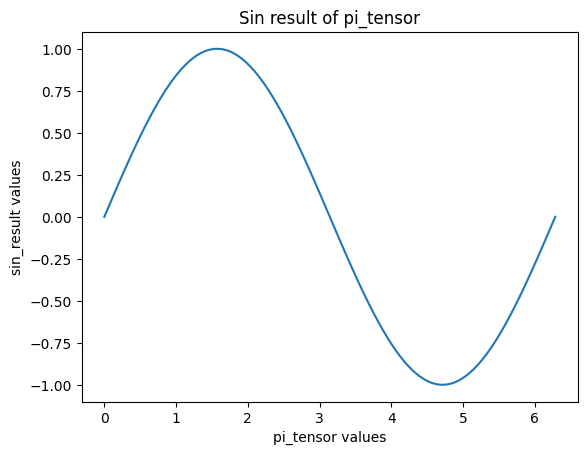

In [47]:
# Plot sin_result: ---

plt.plot(pi_tensor.numpy(), sin_result.numpy()) # Plot the sin_result against the pi_tensor values using matplotlib
plt.title("Sin result of pi_tensor") # Set the title of the plot
plt.xlabel("pi_tensor values") # Set the x-axis label of the plot
plt.ylabel("sin_result values") # Set the y-axis label of the plot
plt.show() # Display the plot

If you know the trigonometric function, you will notice this is the diagram of the sin result in the range 0 to 360 degrees.


<!--Empty Space for separating topics-->


<h3>Practice</h3>


Construct a tensor with 25 steps in the range 0 to π/2. Print out the Maximum and Minimum number. Also, plot  a graph showing the diagram that shows the result.


Max Number:  tensor(1.5708)
Min Number tensor(0.)


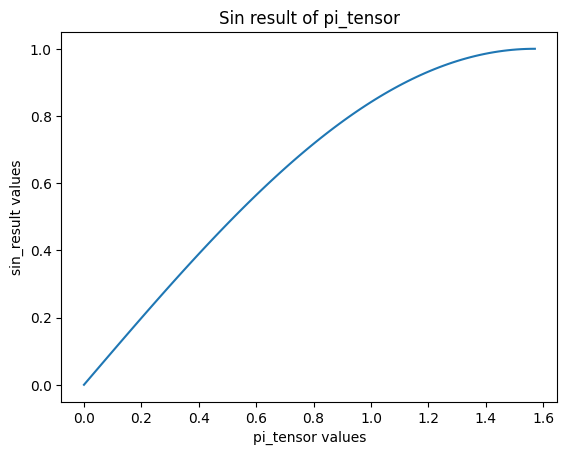

In [48]:
# Practice: Create your tensor, print max and min number, plot the sin result diagram: ---

# Type your code here:
pi_tensor = torch.linspace(0, np.pi/2, 100) # Create a tensor with 100 evenly spaced values between 0 and pi/2 using linspace
print("Max Number: ", pi_tensor.max()) # Print the maximum value in the pi_tensor
print("Min Number", pi_tensor.min()) # Print the minimum value in the pi_tensor
sin_result = torch.sin(pi_tensor) # Calculate the sin result of each element in the pi_tensor
plt.plot(pi_tensor.numpy(), sin_result.numpy()) # Plot the sin_result against the pi_tensor values using matplotlib
plt.title("Sin result of pi_tensor") # Set the title of the plot
plt.xlabel("pi_tensor values") # Set the x-axis label of the plot
plt.ylabel("sin_result values") # Set the y-axis label of the plot
plt.show() # Display the plot 

Double-click <b>here</b> for the solution.
<!-- 
pi_tensor = torch.linspace(0, np.pi/2, 100)
print("Max Number: ", pi_tensor.max())
print("Min Number", pi_tensor.min())
sin_result = torch.sin(pi_tensor)
plt.plot(pi_tensor.numpy(), sin_result.numpy())
-->


<!--Empty Space for separating topics-->


<!-- <h2 id="Tensor_Op">Tensor Operations</h2>
 -->
 ## Tensor Operations


In the following section, you'll work with operations that you can apply to a tensor.


<!--Empty Space for separating topics-->


<h3>Tensor Addition</h3>


You can perform addition between two tensors.


Create a tensor <code>u</code> with 1 dimension and 2 elements. Then, create another tensor <code>v</code> with the same number of dimensions and the same number of elements:


In [77]:
# Create two sample tensors: ---

u = torch.tensor([1, 0]) # Create a tensor u with values [1, 0]
v = torch.tensor([0, 1]) # Create a tensor v with values [0, 1]

Add <code>u</code> and <code>v</code> together:


In [78]:
# Add u and v: ---- Tensor addition is performed element-wise, meaning that the corresponding elements of the two tensors are added together to produce a new tensor. In this case, the first element of u (1) is added to the first element of v (0) to produce the first element of w (1), and the second element of u (0) is added to the second element of v (1) to produce the second element of w (1). The resulting tensor w has the same shape as u and v, and contains the sum of their corresponding elements.

w = u + v         # Add the two tensors u and v element-wise to produce a new tensor w
print("The input tensor u: ", u) # Print the input tensor u
print("The input tensor v: ", v) # Print the input tensor v
print("The result tensor: ", w) # Print the resulting tensor w after adding u and v

The input tensor u:  tensor([1, 0])
The input tensor v:  tensor([0, 1])
The result tensor:  tensor([1, 1])


The result is <code>tensor([1, 1])</code>. The behavior is <i>[1 + 0, 0 + 1]</i>.


Plot the result to to get a clearer picture.


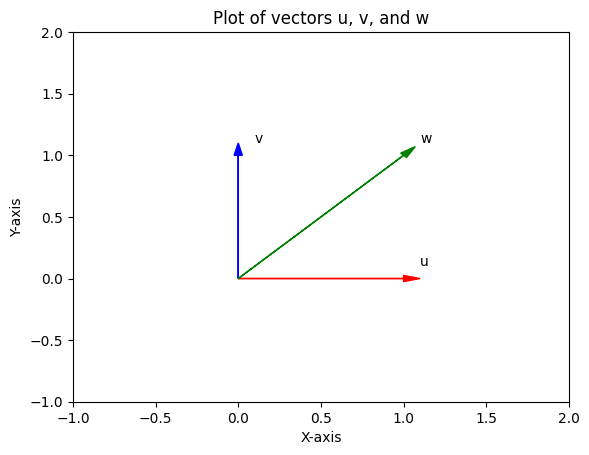

In [79]:
# Plot u, v, w: ---

plotVec([
    {"vector": u.numpy(), "name": 'u', "color": 'r'},
    {"vector": v.numpy(), "name": 'v', "color": 'b'},
    {"vector": w.numpy(), "name": 'w', "color": 'g'}
])  # Plot the vectors u, v, and w using the plotVec function defined earlier
plt.title("Plot of vectors u, v, and w") # Set the title of the plot
plt.xlim(-1, 2) # Set the x-axis limits of the plot
plt.ylim(-1, 2) # Set the y-axis limits of the plot
plt.xlabel("X-axis") # Set the x-axis label of the plot
plt.ylabel("Y-axis") # Set the y-axis label of the plot
plt.show() # Display the plot

<!--Empty Space for separating topics-->


<h3>Try</h3> 


Implement the tensor subtraction with <code>u</code> and <code>v</code> as u-v.


In [80]:
# Try by yourself to get a result of u-v: --- Tensor subtraction is performed element-wise, meaning that the corresponding elements of the two tensors are subtracted from each other to produce a new tensor. In this case, the first element of u (1) is subtracted by the first element of v (0) to produce the first element of the result tensor (1), and the second element of u (0) is subtracted by the second element of v (1) to produce the second element of the result tensor (-1). The resulting tensor has the same shape as u and v, and contains the difference of their corresponding elements.

u = torch.tensor([1, 0]) # Create a tensor u with values [1, 0]
v = torch.tensor([0, 1]) # Create a tensor v with values [0, 1]
# My Try: 
print("The input tensor u: ", u) # Print the input tensor u
print("The input tensor v: ", v) # Print the input tensor v
print("The result tensor: ", u-v) # Print the resulting tensor after subtracting v from u

The input tensor u:  tensor([1, 0])
The input tensor v:  tensor([0, 1])
The result tensor:  tensor([ 1, -1])


Double-click <b>here</b> for the solution.
<!--
print("The result tensor: ", u-v)
-->


Tensors must be of the same data type to perform addition as well as other operations.If you uncomment the  following code and try to run it you will get an error as the two tensors are of two different data types. **NOTE This lab was created on a older PyTorch version so in the current version we are using this is possible and will produce a float64 tensor.**


In [81]:
#
torch.tensor([1,2,3],dtype=torch.int64)+torch.tensor([1,2,3],dtype=torch.float64)

tensor([2., 4., 6.], dtype=torch.float64)

<!--Empty Space for separating topics-->


You can add a scalar to the tensor. Use <code>u</code> as the sample tensor:


In [82]:
# tensor + scalar: --- When adding a scalar to a tensor, the scalar is added to each element of the tensor.

u = torch.tensor([1, 2, 3, -1]) # Create a tensor u with values [1, 2, 3, -1]
v = u + 1                       # Add the scalar value 1 to each element of the tensor u to produce a new tensor v
print ("Addition Result: ", v)  # Print the resulting tensor v after adding the scalar value 1 to each element of the tensor u

Addition Result:  tensor([2, 3, 4, 0])


The result is simply adding 1 to each element in tensor <code>u</code> as shown in the following image:


<img src="https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/DL0110EN/notebook_images%20/chapter%201/brodcasting.gif" width="500" alt="tensor addition">


<!--Empty Space for separating topics-->


<h3>Tensor Multiplication </h3>


Now, you'll review the multiplication between a tensor and a scalar.


Create a tensor with value <code>[1, 2]</code> and then multiply it by 2:


In [87]:
# tensor * scalar : Tensor multiplication by a scalar is performed element-wise, meaning that each element of the tensor is multiplied by the scalar value to produce a new tensor. In this case, each element of the tensor u is multiplied by the scalar value 2 to produce a new tensor v. The resulting tensor v has the same shape as u, and contains the product of each element of u and the scalar value 2.

u = torch.tensor([1, 2])  # Create a tensor u with values [1, 2]
v = 2 * u                 # Multiply each element of the tensor u by the scalar value 2 to produce a new tensor v
print("The result of 2 * u: ", v) # Print the resulting tensor v after multiplying each element of the tensor u by the scalar value 2

The result of 2 * u:  tensor([2, 4])


The result is <code>tensor([2, 4])</code>, so the code <code>2 * u</code> multiplies each element in the tensor by 2. This is how you get the product between a vector or matrix and a scalar in linear algebra.


<!--Empty Space for separating topics-->


You can use multiplication between two tensors.


Create two tensors <code>u</code> and <code>v</code> and then multiply them together:


In [89]:
# tensor * tensor: --- Element-wise multiplication of two tensors.

u = torch.tensor([1, 2]) # Create a tensor u with values [1, 2]
v = torch.tensor([3, 2]) # Create a tensor v with values [3, 2]
w = u * v  # Multiply the corresponding elements of the tensors u and v element-wise to produce a new tensor w
print("The input tensor u: ", u) # Print the input tensor u
print("The input tensor v: ", v) # Print the input tensor v
print ("The result of u * v: ", w) # Print the resulting tensor w after multiplying the corresponding elements of the tensors u and v element-wise

The input tensor u:  tensor([1, 2])
The input tensor v:  tensor([3, 2])
The result of u * v:  tensor([3, 4])


The result is simply <code>tensor([3, 4])</code>. This result is achieved by multiplying every element in <code>u</code> with the corresponding element in the same position <code>v</code>, which is similar to <i>[1 * 3, 2 * 2]</i>.


<!--Empty Space for separating topics-->


<h3>Dot Product</h3>


The dot product is a special operation for a vector that you can use in Torch.


Here is the dot product of the two tensors <code>u</code> and <code>v</code>:


In [90]:
# Calculate dot product of u, v: --- The dot product of two vectors is a scalar value that is calculated by multiplying the corresponding elements of the two vectors and summing the results. In this case, the dot product of the tensors u and v is calculated by multiplying the first element of u (1) by the first element of v (3), and adding it to the product of the second element of u (2) and the second element of v (2). The resulting scalar value is 7.

u = torch.tensor([1, 2]) # Create a tensor u with values [1, 2]
v = torch.tensor([3, 2]) # Create a tensor v with values [3, 2]

print("The input tensor u: ", u) # Print the input tensor u
print("The input tensor v: ", v) # Print the input tensor v
print("The Dot Product is: ", torch.dot(u, v)) # Print the dot product of the tensors u and v using the torch.dot() function

The input tensor u:  tensor([1, 2])
The input tensor v:  tensor([3, 2])
The Dot Product is:  tensor(7)


The result is <code>tensor(7)</code>. The function is <i>1 x 3 + 2 x 2 = 7</i>.


<!--Empty Space for separating topics-->


<h3>Practice</h3>


Convert the list <i>[-1, 1]</i> and <i>[1, 1]</i> to tensors <code>u</code> and <code>v</code>. Then, plot the tensor <code>u</code> and <code>v</code> as a vector by using the function <code>plotVec</code> and find the dot product:


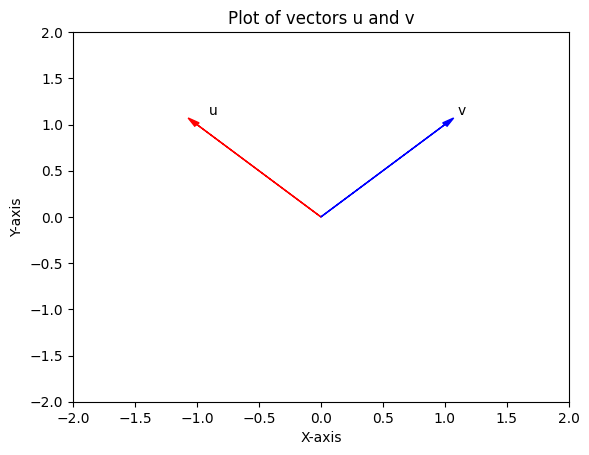

The Dot Product is 0
The Dot Product is tensor(0)


In [92]:
# Practice: calculate the dot product of u and v, and plot out two vectors: --

# Type your code here:
u= torch.tensor([-1, 1]) # Create a tensor u with values [-1, 1]
v= torch.tensor([1, 1])  # Create a tensor v with values [1, 1]
plotVec([
    {"vector": u.numpy(), "name": 'u', "color": 'r'},
    {"vector": v.numpy(), "name": 'v', "color": 'b'}
]) # Plot the vectors u and v using the plotVec function defined earlier
plt.title("Plot of vectors u and v") # Set the title of the plot
plt.xlim(-2, 2) # Set the x-axis limits of the plot
plt.ylim(-2, 2) # Set the y-axis limits of the plot
plt.xlabel("X-axis") # Set the x-axis label of the plot
plt.ylabel("Y-axis") # Set the y-axis label of the plot
plt.show() # Display the plot

# original code, with warning:
#   print("The Dot Product is",np.dot(u, v))

# alternative fix: change to Use torch.dot instead of np.dot here:
print("The Dot Product is", np.dot(u.numpy(), v.numpy()))
print("The Dot Product is", torch.dot(u, v)) # same as above, but using torch.dot instead of np.dot



Double-click <b>here</b> for the solution.
<!-- 
u= torch.tensor([-1, 1])
v= torch.tensor([1, 1])
plotVec([
    {"vector": u.numpy(), "name": 'u', "color": 'r'},
    {"vector": v.numpy(), "name": 'v', "color": 'b'}
])
print("The Dot Product is",np.dot(u, v))
 -->


<!--Empty Space for separating topics-->


See <a href="https://docs.scipy.org/doc/numpy-1.13.0/user/basics.broadcasting.html">Broadcasting</a> for more information on numpy that is similar to PyTorch.


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a/">Mavis Zhou</a> 


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-21  | 2.0  | Shubham  |  Migrated Lab to Markdown and added to course repo in GitLab |

-->


<hr>


## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
